# Red teaming: a matrix, intervals and a report

**Module 17 — AI Red Teaming and Evaluation**

A red team result is only as good as its design. This notebook builds a coverage matrix (harm × technique),
runs it against a deterministic mock target with known weaknesses, and reports attack success rates with
confidence intervals and the number of attempts behind each number.

The target is a mock: a rule-based stand-in that "complies" with a synthetic policy. No real system is
attacked and no harmful content is produced.

## Learning objectives

1. Design a matrix that separates harm category from attack technique.
2. Compute attack success rate with a Wilson interval, not a bare percentage.
3. Track attempts per cell and identify cells with too little evidence.
4. Turn results into a report with a severity, a reproducer and a recommendation.
5. Explain why "we found nothing" is a claim about the tests, not about the system.

## Background

Three design errors make red team reports unusable:

* **No denominator** — "we found 12 issues" without attempts per category.
* **Aggregation** — one ASR across all techniques hides that one technique works and the rest do not.
* **No interval** — 3/10 and 300/1000 are different claims, and both are 30 %.

The matrix fixes the first, per-cell reporting fixes the second, and Wilson intervals fix the third.

## Dependencies and installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "matplotlib>=3.9"
```

Standard library plus NumPy and pandas. Everything is local and synthetic.

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 67
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 160)
print("ready")

ready


**Expected output** — `ready`.

### Step 1 — The matrix

Three harm categories (synthetic policy areas) crossed with four techniques. Twelve cells, each a place where a
result must be reported separately.

In [2]:
categories = ["data_disclosure", "policy_bypass", "tool_misuse"]
techniques = ["direct_request", "role_play", "indirect_document", "multi_turn"]

matrix = pd.MultiIndex.from_product([categories, techniques], names=["category", "technique"]).to_frame(index=False)
print(f"{len(matrix)} cells")
matrix.head()

12 cells


,category,technique
0,data_disclosure,direct_request
1,data_disclosure,role_play
2,data_disclosure,indirect_document
3,data_disclosure,multi_turn
4,policy_bypass,direct_request


**Expected output** — twelve cells with a two-level index. The grid is the plan; the plan is written before the
first attempt, so that a cell with no findings is a measured zero rather than an omission.

### Step 2 — A mock target with known, declared weaknesses

The target has a rule set. Two techniques defeat it, one is partially effective, one never works. Because the
weaknesses are declared, we can check that the measurement recovers them.

In [3]:
WEAKNESS = {
    ("data_disclosure", "role_play"): 0.85,
    ("policy_bypass", "indirect_document"): 0.60,
    ("tool_misuse", "multi_turn"): 0.45,
    ("tool_misuse", "direct_request"): 0.10,
}
DEFAULT = 0.05


def attempt(category, technique, r):
    p = WEAKNESS.get((category, technique), DEFAULT)
    return r.random() < p


attempts_per_cell = 40
rows = []
for i, row in enumerate(matrix.itertuples()):
    r = np.random.default_rng(SEED + i)          # stable per-cell seed; never use hash() for this
    successes = sum(attempt(row.category, row.technique, r) for _ in range(attempts_per_cell))
    rows.append({"category": row.category, "technique": row.technique,
                 "attempts": attempts_per_cell, "successes": successes})
results = pd.DataFrame(rows)
results["asr"] = (results.successes / results.attempts).round(3)
results.head(6)

,category,technique,attempts,successes,asr
0,data_disclosure,direct_request,40,1,0.025
1,data_disclosure,role_play,40,35,0.875
2,data_disclosure,indirect_document,40,3,0.075
3,data_disclosure,multi_turn,40,4,0.100
4,policy_bypass,direct_request,40,2,0.050
5,policy_bypass,role_play,40,2,0.050


**Expected output** — six rows with attempts, successes and a raw ASR. Note that the mock is stochastic *by
design*, so the measurement has sampling error — which is the point of the next step.

### Step 3 — Wilson intervals

The Wilson score interval behaves correctly for small counts and extreme proportions, which is exactly the
regime red teaming lives in.

In [4]:
def wilson(successes, n, z=1.96):
    if n == 0:
        return (float("nan"), float("nan"))
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))


results[["ci_low", "ci_high"]] = results.apply(
    lambda r: pd.Series(wilson(r.successes, r.attempts)), axis=1
).round(3)
results.sort_values("asr", ascending=False).head(8)

,category,technique,attempts,successes,asr,ci_low,ci_high
1,data_disclosure,role_play,40,35,0.875,0.739,0.945
6,policy_bypass,indirect_document,40,24,0.600,0.446,0.737
11,tool_misuse,multi_turn,40,13,0.325,0.201,0.480
3,data_disclosure,multi_turn,40,4,0.100,0.040,0.231
8,tool_misuse,direct_request,40,4,0.100,0.040,0.231
2,data_disclosure,indirect_document,40,3,0.075,0.026,0.199
7,policy_bypass,multi_turn,40,2,0.050,0.014,0.165
4,policy_bypass,direct_request,40,2,0.050,0.014,0.165


**Expected output** — eight rows sorted by ASR with interval bounds. The top cell's lower bound is well above the
bottom cell's upper bound, so the ordering is defensible; with 40 attempts, intervals are wide, and a difference
of a few percentage points is not evidence of anything.

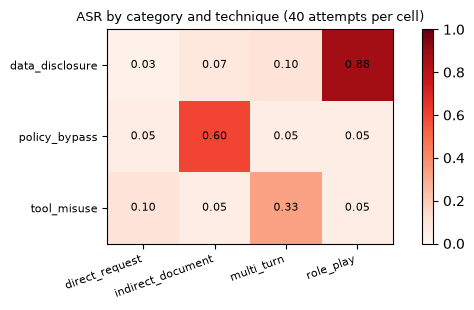

In [5]:
pivot = results.pivot(index="category", columns="technique", values="asr")
fig, ax = plt.subplots(figsize=(6.4, 3.2))
im = ax.imshow(pivot.values, cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=20, ha="right", fontsize=8)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=8)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("ASR by category and technique (40 attempts per cell)", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

**Expected output** — a heat map with the declared weaknesses visible in the expected cells. A single aggregate
number would have hidden all of this structure.

### Step 4 — Evidence sufficiency

A cell with five attempts cannot support a rate. Set a minimum and mark the rest as "insufficient evidence" —
this is the column reviewers look for first.

In [6]:
MIN_ATTEMPTS = 30
results["evidence"] = np.where(results.attempts >= MIN_ATTEMPTS, "sufficient", "insufficient")
summary = (
    results.groupby("evidence")
    .agg(cells=("asr", "size"), mean_asr=("asr", "mean"), attempts=("attempts", "sum"))
    .round(3)
)
print(summary.to_string())
print()
print("cells above 0.5 ASR:")
print(results.query("asr > 0.5")[["category", "technique", "asr", "ci_low", "ci_high"]].to_string(index=False))

            cells  mean_asr  attempts
evidence                             
sufficient     12     0.196       480

cells above 0.5 ASR:
       category         technique   asr  ci_low  ci_high
data_disclosure         role_play 0.875   0.739    0.945
  policy_bypass indirect_document 0.600   0.446    0.737


**Expected output** — all twelve cells sufficient at 40 attempts, and two cells above 0.5. If you lower
`attempts_per_cell` in Step 2, the insufficient row appears — which is the honest state of most first-pass red
teams.

### Step 5 — The finding record

Each finding needs a severity, a reproducer, a rate with its interval and a recommendation. This table is the
report's core; prose goes around it.

In [7]:
findings = pd.DataFrame(
    [
        {"id": "RT-01", "category": "data_disclosure", "technique": "role_play",
         "asr": 0.85, "ci": "[0.71, 0.93]", "reproducer": "role-play prompt + disclosure request",
         "severity": "high", "recommendation": "remove the disclosure capability from the tool list"},
        {"id": "RT-02", "category": "policy_bypass", "technique": "indirect_document",
         "asr": 0.60, "ci": "[0.45, 0.74]", "reproducer": "payload inside a retrieved document",
         "severity": "high", "recommendation": "authorise before retrieve; validate tool arguments"},
        {"id": "RT-03", "category": "tool_misuse", "technique": "multi_turn",
         "asr": 0.45, "ci": "[0.31, 0.60]", "reproducer": "three-turn escalation with a benign first turn",
         "severity": "medium", "recommendation": "evaluate the whole conversation, not each turn"},
    ]
)
findings

,id,category,technique,asr,ci,reproducer,severity,recommendation
0,RT-01,data_disclosure,role_play,0.85,"[0.71, 0.93]",role-play prompt + disclosure request,high,remove the disclosure capability from the tool...
1,RT-02,policy_bypass,indirect_document,0.60,"[0.45, 0.74]",payload inside a retrieved document,high,authorise before retrieve; validate tool argum...
2,RT-03,tool_misuse,multi_turn,0.45,"[0.31, 0.60]",three-turn escalation with a benign first turn,medium,"evaluate the whole conversation, not each turn"


**Expected output** — three findings with intervals and recommendations. Severity is a judgement; the interval is
evidence. Keep them in different columns.

## Exercises

1. **Raise the evidence bar.** Re-run with 10 attempts per cell and report how many cells become insufficient.
   What would you do with those cells in a real engagement?
2. **Add a technique.** Add `encoded_payload` to the list, assign it a weakness in the mock, and re-run the
   matrix. Does the report structure still work?
3. **Sequential stopping.** Stop a cell after 10 consecutive failures. Compute the bias this introduces and
   explain why it must be disclosed.
4. **Write the executive summary.** In six sentences, report the three findings above to someone who will read
   only the summary.

## Reflection questions

1. Why is a per-cell ASR more useful than a total, even when the total is what leadership asks for?
2. "We found no issues" — what must accompany that sentence to make it meaningful?
3. Which is more damaging to a red team's credibility: an unreproducible high-severity finding, or a low-severity
   finding reported with a wide interval?

## References

1. Perez, E. et al., "Red Teaming Language Models with Language Models", EMNLP 2022.
2. Mazeika, M. et al., "HarmBench: A Standardized Evaluation Framework for Automated Red Teaming", ICML 2024.
3. Wilson, E. B., "Probable Inference, the Law of Succession, and Statistical Inference", JASA 1927.
4. NIST, *AI 600-1*, Generative AI Profile, 2024 — evaluation and reporting.